# 1.1 — First Scikit-Learn Model: Linear Regression

**Objective:** Build a linear regression model using Scikit-Learn to predict house prices from house sizes.

**Concepts covered:**
- Features (`X`) and target (`y`)
- Creating a `LinearRegression` estimator
- Training with `fit()`
- Making predictions with `predict()`
- Understanding the learned coefficient (`coef_`) and intercept (`intercept_`)

**Dataset:** A small example dataset of house sizes and prices.

**Important note:** Scikit-Learn's `LinearRegression` uses ordinary least squares, not gradient descent.


In [1]:
import numpy as np
from sklearn.linear_model import LinearRegression

In [2]:
# Features: house sizes
X = np.array([
    [50],
    [60],
    [80],
    [100],
    [120]
])

# Targets: house prices in lakh taka
y = np.array([25, 30, 40, 50, 60])

#Create a model
model = LinearRegression()

#Train the model
model.fit(X, y)

#Predict the price of a 90 m^2 house
prediction = model.predict([[90]])

In [3]:
print(f"Prediction : {prediction}")
print(f"Coefficient (w) : {model.coef_}")
print(f"Bias/Intercept (b) : {model.intercept_}")

Prediction : [45.]
Coefficient (w) : [0.5]
Bias/Intercept (b) : 7.105427357601002e-15


## 1.2 — Understanding Features, Targets, and Dataset Shapes

**Objective:** Understand how supervised-learning datasets are represented in NumPy and Scikit-Learn.

**Concepts covered:**
- Samples (rows) and features (columns)
- Input features (`X`) and target (`y`)
- The shape of the feature matrix: `(n_samples, n_features)`
- The usual shape of a single-output target array: `(n_samples,)`
- How adding a feature changes the dataset shape

**Key takeaway:** Each row of `X` represents one sample, and each column represents one feature. The target `y` contains the value the model learns to predict for each sample.

In [4]:
import numpy as np

In [5]:
# Features: size, bedrooms, age
X = np.array([
    [50, 2, 10],
    [70, 3, 5],
    [90, 3, 2],
    [120, 4, 1]
])

# Target: house prices
y = np.array([25, 35, 45, 60])

print(f"X shape : {X.shape}")
print(f"y shape : {y.shape}")

X shape : (4, 3)
y shape : (4,)


## 1.3 — Understanding the Scikit-Learn Estimator API

**Objective:** Understand how Scikit-Learn objects are created, trained, and used.

**Concepts covered:**
- Estimators, predictors, and transformers
- The purpose of `fit()` and `predict()`
- Learned attributes such as `coef_` and `intercept_`
- The difference between creating a model and training it
- Estimator: An object that learns from data, typically through fit().
- Predictor: An object that makes predictions using predict().
- Transformer: An object that transforms data using transform().

In [6]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Training data
X = np.array([[50], [60], [80], [100], [120]])
y = np.array([25, 30, 40, 50, 60])

model = LinearRegression()

model.fit(X, y)

predictions = model.predict([[90], [110]])

print(f"Predictions: {predictions}")
print(f"Coefficient: {model.coef_}")
print(f"Intercept: {model.intercept_}")
print(f"Number of features: {model.n_features_in_}")

Predictions: [45. 55.]
Coefficient: [0.5]
Intercept: 7.105427357601002e-15
Number of features: 1


## 1.4 — Transformers: `transform()` and `fit_transform()`

**Objective:** Understand how Scikit-Learn transformers learn transformation rules and apply them to data.

**Concepts covered:**
- What a transformer does
- `StandardScaler`
- `fit()`, `transform()`, and `fit_transform()`
- Why the scaler learns statistics from training data
- Why the same fitted scaler should be used on new data

- **`StandardScaler()`**: Creates a transformer that standardizes numerical features.
- **`fit(X)`**: Learns the mean and scaling factor of each feature.
- **`transform(X)`**: Transforms data using previously learned statistics.
- **`fit_transform(X)`**: Learns statistics and transforms the data in one step.
- **`scaler.mean_`**: Stores learned feature means.
- **`scaler.scale_`**: Stores learned scaling factors.

**Example:**
```python
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
```

**Key rule:** Fit on training data; use the same fitted scaler to transform test or new data.

In [7]:
import numpy as np
from sklearn.preprocessing import StandardScaler

In [8]:
#Two features: house size and number of bedrooms
X_before = np.array([
    [50, 2],
    [80, 3],
    [120, 4],
    [100, 3]
])

#Create the transformer
scaler = StandardScaler()

#Learn the statistics and transform the data
X_scaled = scaler.fit_transform(X)

print(f"X originally :")
print(X_before)
print("\n")
print(f"X after scaling :")
print(X_scaled)

print("\nLearned means:")
print(scaler.mean_)

print("\nLearned standard deviations:")
print(scaler.scale_)

X originally :
[[ 50   2]
 [ 80   3]
 [120   4]
 [100   3]]


X after scaling :
[[-1.2493901 ]
 [-0.85895569]
 [-0.07808688]
 [ 0.70278193]
 [ 1.48365074]]

Learned means:
[82.]

Learned standard deviations:
[25.61249695]


## 1.5 — Hyperparameters vs. Learned Parameters

### 1. Definitions

- **Hyperparameters:** Settings chosen before training that control model behavior.
- **Learned parameters:** Values estimated by the model from training data during `fit()`.

### 2. Example: `LinearRegression`

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression(fit_intercept=True)
model.fit(X, y)

print(model.coef_)
print(model.intercept_)
```

- `fit_intercept=True`: Hyperparameter chosen by the user.
- `coef_`: Learned coefficient.
- `intercept_`: Learned intercept.

### 3. Why Do Hyperparameters Matter?

```python
model1 = LinearRegression(fit_intercept=True)
model2 = LinearRegression(fit_intercept=False)
```

- **Model 1:** Learns the coefficient and intercept.
- **Model 2:** Learns the coefficient while forcing the intercept to zero.

The hyperparameter choice changes how the model fits the data.

**Key takeaway:** Hyperparameters control aspects of model behavior; learned parameters are estimated from data.

**Note:** `coef_` and `intercept_` become available after fitting the model.

| Situation | Setting | Reason |
|---|---|---|
| House-price prediction | `True` | No reason to assume the price must be zero when all features are zero. |
| Student-score prediction | `True` | The relationship may have a nonzero intercept. |
| Predicting distance from time at a constant speed, measured from the starting point | Possibly `False` | At time zero, distance is physically zero. |
| A model whose relationship is known to pass through the origin | `False` | Enforces that known constraint. |

In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression(fit_intercept=True)
model.fit(X, y)

print(model.coef_)
print(model.intercept_)

[0.5]
7.105427357601002e-15


In [10]:
from sklearn.linear_model import SGDRegressor

model = SGDRegressor(
    learning_rate="constant",
    eta0=0.01,
    max_iter=1000
)

model.fit(X, y)

SGDRegressor(learning_rate='constant')

In [11]:
import numpy as np
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3]])
y = np.array([3, 5, 7])

model1 = LinearRegression(fit_intercept=True)
model1.fit(X, y)

model2 = LinearRegression(fit_intercept=False)
model2.fit(X, y)

print("Model 1:", model1.coef_, model1.intercept_)
print("Model 2:", model2.coef_, model2.intercept_)

Model 1: [2.] 1.0000000000000009
Model 2: [2.42857143] 0.0


## 1.6.1 — Built-in Toy Datasets

Scikit-Learn provides small, ready-to-use datasets for practicing machine learning without downloading external files.

### Example: `load_diabetes()`

### Key concepts

- `data.data`: Contains the input features (`X`).
- `data.target`: Contains the target values (`y`).
- `data.feature_names`: Contains the names of the features.
- `load_diabetes()`: Loads a built-in regression dataset.

**Dataset shape:**
- `X.shape`: `(442, 10)`
- `y.shape`: `(442,)`

**Interpretation:** The dataset contains 442 samples, 10 features per sample, and one target value per sample. The target measures diabetes disease progression, not a diabetes diagnosis.

**When to use:** Practicing machine learning algorithms with an existing dataset.

In [12]:
from sklearn.datasets import load_diabetes

data = load_diabetes()

X = data.data
y = data.target

print(f"X shape : {X.shape}")
print(f"y shape : {y.shape}")
print(f"Feature Names : {data.feature_names}")

X shape : (442, 10)
y shape : (442,)
Feature Names : ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


## 1.6.2 — Synthetic Datasets

A synthetic dataset is data generated programmatically rather than collected from real-world observations.

Scikit-Learn provides functions such as `make_regression()` to generate synthetic regression data.

### Example: `make_regression()`

### Important arguments

| Argument | Meaning |
|---|---|
| `n_samples=100` | Generates 100 samples. |
| `n_features=2` | Each sample has 2 features. |
| `noise=10` | Adds random noise to the target values. |
| `random_state=40` | Makes the generated data reproducible. |

**Expected shapes:**
- `X.shape`: `(100, 2)`
- `y.shape`: `(100,)`

### Why use synthetic data?

- Control the number of samples and features.
- Experiment with noise and understand its effect.
- Test algorithms without downloading datasets.
- Practice with data whose generating process is known.

**Key distinction:**
- **Toy datasets:** Existing, built-in datasets.
- **Synthetic datasets:** Artificially generated datasets.

**Related function:** `make_classification()` generates synthetic classification data, which we'll explore when studying classification.

In [13]:
from sklearn.datasets import make_regression

X, y = make_regression (
    n_samples = 100,
    n_features = 2,
    noise = 10,
    random_state = 40
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100, 2)
y shape: (100,)


## 1.7 — Basic Supervised-Learning Workflow

Supervised learning uses labeled data to learn a relationship between input features (`X`) and target values (`y`).

### Steps in the workflow

1. **Obtain the dataset:** Use a built-in, synthetic, or real-world dataset.
2. **Separate features and target:** `X` contains input features; `y` contains the target values to predict.
3. **Split the dataset:** Divide the data into training and testing sets.
4. **Choose a model:** Select an appropriate algorithm, such as `LinearRegression`.
5. **Train the model:** Use `fit()` with the training features and targets.
6. **Make predictions:** Use `predict()` on the test features.
7. **Evaluate the model:** Compare predictions with the actual test targets using suitable evaluation metrics.

### Train-test split

A train-test split helps evaluate how well a model generalizes to unseen data.

For an 80/20 split of 1,000 samples:

- **Training set:** 800 samples (80%).
- **Testing set:** 200 samples (20%).

The training set is used to fit the model. The test set is reserved for evaluating its performance.

### Important Scikit-Learn methods

| Method | Purpose |
|---|---|
| `fit()` | Learns from training data. |
| `predict()` | Generates predictions for input features. |
| `score()` | Returns a model-specific evaluation score. For `LinearRegression`, this is the coefficient of determination, \(R^2\). |

### Key rule

Do not train the model on the test set. Keep the test data separate so it provides a fairer assessment of performance on unseen samples.

**Note:** `train_test_split()` and evaluation metrics will be studied in more detail later in the roadmap.

In [ ]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generate custom Dataset
X, y = make_regression(
    n_samples = 100,
    n_features = 2,
    noise = 10,
    random_state = 40
)


# Split the dataset into training and test set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 40
)


# Create Model
model = LinearRegression()


# Train the Model
model.fit(X_train, y_train)


# Make prediction
y_pred = model.predict(X_test)


#Evaluate the Model
print(f"MAE : {mean_absolute_error(y_test, y_pred)}")
print(f"MSE : {mean_squared_error(y_test, y_pred)}")
print(f"R^2 : {r2_score(y_test, y_pred)}")


#Inspect a few Prediction
print(f"Actual Values : {y_test[:5]}")
print(f"Predicted Values : {y_pred[:5]}")

### Regression Evaluation Metrics

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted values. Lower is better.

- **MSE (Mean Squared Error):** Measures the average squared difference between actual and predicted values. Lower is better; large errors receive greater penalties.

- **R² (Coefficient of Determination):** Measures how well the model explains variation in the target. A value closer to 1 generally indicates a better fit. It can be negative when the model performs worse than predicting the target mean.

## 2.1 — Simple Linear Regression

### 1. Definition
Simple Linear Regression is a supervised learning algorithm that models the relationship between one input feature and a continuous target using a straight line.

### 2. Mathematical Equation

ŷ = wx + b

- x: Input feature
- ŷ: Predicted target
- w: Slope or coefficient
- b: Intercept or bias

### 3. Slope and Intercept

- **Slope (w):** Determines how much the prediction changes when the input increases by one unit.
- **Intercept (b):** The predicted target when the input is zero.

In Scikit-Learn, `coef_` stores the learned coefficient, while `intercept_` stores the learned intercept.

### 4. How Does the Model Learn?

`LinearRegression` uses Ordinary Least Squares (OLS) to find the coefficient and intercept that minimize the sum of squared residuals.

Residual = Actual value - Predicted value

Objective: Minimize the sum of (actual value - predicted value)² across all training samples.

### 5. Important Points

- `fit()` learns the model parameters from training data.
- `predict()` generates predictions using the learned parameters.
- Standard `LinearRegression` uses OLS, not gradient descent, by default.
- The fitted line does not necessarily pass through every data point.
- Good training performance does not guarantee good performance on unseen data.

In [8]:
import numpy as np
from sklearn.linear_model import LinearRegression

#house size and price
X = np.array([[50], [60], [80], [100], [120]])
y = np.array([27, 29, 43, 48, 63])

model = LinearRegression()
model.fit(X, y)

print(f"Slope : {model.coef_}")
print(f"Intercept : {model.intercept_}")
print(f"Prediction for 90 m^2 house : {model.predict([[90]])}")

Slope : [0.50914634]
Intercept : 0.25
Prediction for 90 m^2 house : [46.07317073]


## 2.2 — How Linear Regression Finds the Best-Fitting Line

### 1. The Problem
Many straight lines can fit a dataset. Linear Regression needs a way to determine which line fits the training data best.

### 2. Residuals
A residual is the difference between an actual value and its predicted value.

**Residual = Actual value − Predicted value**

- Positive residual: The model underpredicts.
- Negative residual: The model overpredicts.
- Zero residual: The prediction is exact.

### 3. Sum of Squared Errors (SSE)
Simply adding residuals can cause positive and negative errors to cancel each other out. Therefore, we square each residual and sum them.

**SSE = Sum of (Actual value − Predicted value)²**

Squaring prevents cancellation and penalizes larger errors more heavily.

### 4. Ordinary Least Squares (OLS)
Scikit-Learn's `LinearRegression` uses Ordinary Least Squares (OLS) to find the coefficient and intercept that minimize the sum of squared residuals on the training data.

The objective is to minimize SSE by choosing suitable values of the slope (w) and intercept (b).

### 5. Important Points
- `fit()` learns the model parameters from training data.
- OLS minimizes the sum of squared residuals.
- The best-fitting line does not necessarily pass through every data point.
- Minimizing training error does not guarantee good performance on unseen data.
- Standard Scikit-Learn `LinearRegression` uses an OLS solver by default, not gradient descent.

**Key takeaway:** Linear Regression finds the line that minimizes the total squared prediction errors on the training data.

## 2.3 — Interpreting a Trained Linear Regression Model

In [10]:
import numpy as np
from sklearn.linear_model import LinearRegression

#house size and price
X = np.array([[50], [60], [80], [100], [120]])
y = np.array([27, 29, 43, 48, 63])

model = LinearRegression()
model.fit(X, y)

print(f"Slope : {model.coef_}")
print(f"Intercept : {model.intercept_}")

new_house = np.array([[90]])
prediction = model.predict(new_house)

print(f"Predicted price for 90 m^2 house : {prediction}")


multiple_houses = np.array([[100], [203], [54]])
prediction = model.predict(multiple_houses)

print(f"Prediction for 100, 203, 54 m^2 houses : {prediction}")

Slope : [0.50914634]
Intercept : 0.25
Predicted price for 90 m^2 house : [46.07317073]
Prediction for 100, 203, 54 m^2 houses : [ 51.16463415 103.60670732  27.74390244]


## 2.4 — Visualizing Linear Regression with Matplotlib

### 1. Why Visualize?
Visualization helps us understand how well a regression line represents the actual data and identify patterns that a numerical score may not reveal.

### 2. Important Plot Elements
- **Scatter plot:** Displays actual observations as individual points.
- **Regression line:** Shows the predictions made by the trained model across input values.
- **Residuals:** Differences between actual values and predictions, represented by vertical distances from the points to the line.

### 3. Important Functions
- `plt.scatter(X, y)`: Plots actual observations.
- `np.linspace(start, stop, num)`: Generates evenly spaced values between a starting and ending value.
- `model.predict(X_line)`: Generates predictions for drawing the regression line.
- `plt.plot(X_line, y_line)`: Draws the regression line.
- `plt.xlabel()` and `plt.ylabel()`: Add axis labels.
- `plt.legend()`: Identifies the plotted elements.
- `plt.show()`: Displays the plot.

### 4. Why Use 100 Points?
Generating 100 evenly spaced input values creates a smooth-looking regression line. This number controls plotting resolution, not the number of training samples or the model's accuracy.

For a straight line, even two distinct input values are theoretically sufficient to draw it.

### 5. Interpreting the Plot
- Points close to the line indicate smaller prediction errors for those observations.
- Points far from the line indicate larger prediction errors.
- A visible curved pattern may suggest that a straight-line model does not adequately capture the relationship.
- A good fit on training data does not guarantee good performance on unseen data.

**Key takeaway:** Visualization helps us inspect a regression model's fit, but proper evaluation on unseen data is still necessary.

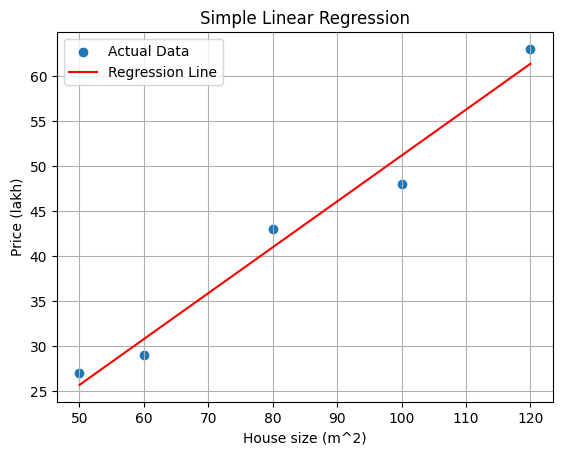

In [17]:
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

X = np.array([[50], [60], [80], [100], [120]])
y = np.array([27, 29, 43, 48, 63])

model = LinearRegression()
model.fit(X, y)


X_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

#.reshape(-1, 1) -> Converts the generated values into the 2D shape expected by Scikit-Learn.

y_line = model.predict(X_line)


plt.scatter(X, y, label="Actual Data")
plt.plot(X_line, y_line, color="red", label="Regression Line")

plt.xlabel("House size (m^2)")
plt.ylabel("Price (lakh)")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(True)